In [9]:
import pandas as pd
import numpy as np
df =pd.read_csv("../Data/ecommerce_sales_raw.csv")
df.head()

,Order_ID,Order_Date,Customer_Name,Category,Product,Quantity,Sales,Profit,City,Payment_Mode
0,ORD0001,10-04-2025,Customer_104,Grocery,Oil,3.0,3864.0,636.83,Bengaluru,Net Banking
1,ORD0002,11-12-2025,Customer_049,Furniture,Table,2.0,12102.0,626.48,Bengaluru,Debit Card
2,ORD0003,01-09-2025,Customer_064,Furniture,Table,4.0,4756.0,692.55,Pune,Debit Card
3,ORD0004,12-12-2025,Customer_053,Books,Data Analytics,5.0,2455.0,359.30,Mumbai,Cash
4,ORD0005,02-01-2025,Customer_134,Grocery,Snacks,4.0,1020.0,97.47,Chennai,Credit Card


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 820 entries, 0 to 819
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       820 non-null    str    
 1   Order_Date     820 non-null    str    
 2   Customer_Name  805 non-null    str    
 3   Category       810 non-null    str    
 4   Product        808 non-null    str    
 5   Quantity       812 non-null    float64
 6   Sales          810 non-null    float64
 7   Profit         810 non-null    float64
 8   City           820 non-null    str    
 9   Payment_Mode   812 non-null    str    
dtypes: float64(3), str(7)
memory usage: 64.2 KB


In [21]:
df.isnull().sum()


Order_ID          0
Order_Date        0
Customer_Name    15
Category         10
Product          12
Quantity          8
Sales            10
Profit           10
City              0
Payment_Mode      8
dtype: int64

In [36]:
#Cleaning — Customer_Name
df["Customer_Name"] = df["Customer_Name"].fillna("Unknown")

In [37]:
df["Customer_Name"].isnull().sum()

np.int64(0)

In [39]:
df[df["Category"].isnull()]

,Order_ID,Order_Date,Customer_Name,Category,Product,Quantity,Sales,Profit,City,Payment_Mode
8,ORD0009,21-06-2025,Customer_104,NaN,Keyboard,2.0,106112.0,22971.19,Chennai,Debit Card
38,ORD0039,16-03-2025,Customer_157,NaN,Desk,2.0,NaN,4397.60,Hyderabad,UPI
163,ORD0164,03-06-2025,Customer_196,NaN,Rice,2.0,1768.0,212.03,Mumbai,Debit Card
243,ORD0244,25-12-2025,Customer_068,NaN,Sofa,3.0,36543.0,10656.10,Bengaluru,UPI
346,ORD0347,11-01-2025,Customer_098,NaN,Power BI,4.0,4696.0,334.71,Mumbai,Cash
491,ORD0492,24-11-2025,Customer_106,NaN,Smartphone,5.0,116345.0,30148.80,Delhi,Debit Card
500,ORD0501,13-06-2025,Customer_161,NaN,Oil,2.0,376.0,109.99,Nagpur,Net Banking
655,ORD0656,19-02-2025,Customer_242,NaN,Jacket,3.0,2709.0,599.85,Nagpur,Credit Card
698,ORD0699,01-06-2025,Customer_237,NaN,Laptop,2.0,124128.0,21231.61,Bengaluru,Debit Card
791,ORD0792,04-11-2025,Customer_115,NaN,Oil,2.0,394.0,60.13,Chennai,Credit Card


In [ ]:
df[["Product","Category"]].drop_duplicates().sort_values("Product")

In [42]:
#step 5 b

category_mapping = (
    df.dropna(subset=["Category"])
      .groupby("Product")["Category"]
      .agg(lambda x: x.mode()[0])
      .to_dict()
)

In [45]:
df["Category"] = df["Category"].fillna(
    df["Product"].map(category_mapping)
)

In [46]:
df["Category"].isnull().sum()


np.int64(0)

In [47]:
df[df["Product"].isnull()]

,Order_ID,Order_Date,Customer_Name,Category,Product,Quantity,Sales,Profit,City,Payment_Mode
122,ORD0123,15-01-2025,Customer_162,Books,NaN,3.0,5340.0,813.46,Delhi,Debit Card
191,ORD0192,15-11-2025,Customer_116,Books,NaN,3.0,4368.0,475.96,Pune,Debit Card
242,ORD0243,09-12-2025,Customer_179,Grocery,NaN,5.0,3615.0,869.32,Bengaluru,Credit Card
260,ORD0261,01-08-2025,Customer_149,Books,NaN,2.0,2310.0,195.84,Bengaluru,Net Banking
282,ORD0283,12-07-2025,Customer_145,Books,NaN,4.0,1416.0,151.76,Chennai,Credit Card
351,ORD0352,07-08-2025,Customer_213,Clothing,NaN,1.0,1826.0,260.87,Mumbai,Net Banking
371,ORD0372,05-01-2025,Customer_122,Furniture,NaN,1.0,2008.0,502.49,Delhi,Net Banking
418,ORD0419,03-09-2025,Customer_244,Books,NaN,1.0,1832.0,373.92,Mumbai,UPI
479,ORD0480,27-04-2025,Customer_166,Electronics,NaN,2.0,3584.0,502.11,Pune,Net Banking
551,ORD0552,07-12-2025,Customer_192,Clothing,NaN,3.0,10710.0,808.28,Hyderabad,Credit Card


In [48]:
df["Product"].isnull().sum()

np.int64(12)

In [49]:
df["Product"] = df["Product"].fillna("Unknown")

In [50]:
df["Product"].isnull().sum()

np.int64(0)

In [51]:
df[df["Quantity"].isnull()]

,Order_ID,Order_Date,Customer_Name,Category,Product,Quantity,Sales,Profit,City,Payment_Mode
92,ORD0093,03-09-2025,Customer_022,Furniture,Bookshelf,NaN,13808.0,1580.63,Bengaluru,Cash
155,ORD0156,30-08-2025,Customer_069,Electronics,Monitor,NaN,69768.0,16860.42,Nagpur,UPI
400,ORD0401,23-10-2025,Customer_225,Clothing,T-Shirt,NaN,4754.0,1060.56,Delhi,UPI
416,ORD0417,26-01-2025,Customer_153,Clothing,T-Shirt,NaN,5552.0,1623.02,Chennai,Net Banking
474,ORD0475,04-07-2025,Customer_069,Books,Python Basics,NaN,1632.0,241.62,Delhi,Credit Card
522,ORD0523,03-12-2025,Customer_066,Grocery,Snacks,NaN,4088.0,1134.01,Bengaluru,Debit Card
525,ORD0526,10-12-2025,Customer_203,Electronics,Keyboard,NaN,155436.0,22187.47,Bengaluru,UPI
601,ORD0602,06-02-2025,Customer_026,Electronics,Keyboard,NaN,28270.0,2312.66,Pune,Cash


In [52]:
df["Quantity"].median()

np.float64(3.0)

In [53]:
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())

In [54]:
df["Quantity"].isnull().sum()

np.int64(0)

In [55]:
#step 5 e
df[df["Sales"].isnull()]

,Order_ID,Order_Date,Customer_Name,Category,Product,Quantity,Sales,Profit,City,Payment_Mode
38,ORD0039,16-03-2025,Customer_157,Furniture,Desk,2.0,NaN,4397.60,Hyderabad,UPI
88,ORD0089,15-10-2025,Customer_120,Books,Python Basics,5.0,NaN,3555.78,Chennai,Debit Card
158,ORD0159,12-11-2025,Customer_130,Furniture,Sofa,4.0,NaN,11213.91,Hyderabad,Net Banking
169,ORD0170,09-09-2025,Customer_097,Clothing,T-Shirt,3.0,NaN,419.04,Hyderabad,Cash
187,ORD0188,11-04-2025,Customer_186,Grocery,Rice,1.0,NaN,286.39,Hyderabad,Net Banking
435,ORD0436,12-07-2025,Customer_051,Books,SQL Guide,1.0,NaN,293.37,Bengaluru,Debit Card
559,ORD0560,05-12-2025,Customer_020,Clothing,Jacket,4.0,NaN,386.50,Mumbai,Net Banking
607,ORD0608,05-04-2025,Customer_226,Grocery,Rice,1.0,NaN,114.16,Chennai,Debit Card
701,ORD0702,28-12-2025,Customer_125,Grocery,Oil,3.0,NaN,225.09,Hyderabad,Net Banking
730,ORD0731,23-09-2025,Customer_064,Clothing,Hoodie,4.0,NaN,1234.85,Nagpur,Net Banking


In [57]:
product_sales_median = df.groupby("Product")["Sales"].transform("median")

In [58]:
df["Sales"] = df["Sales"].fillna(product_sales_median)

In [61]:
df["Sales"].isnull().sum()

np.int64(0)

In [62]:
df[df["Profit"].isnull()]

,Order_ID,Order_Date,Customer_Name,Category,Product,Quantity,Sales,Profit,City,Payment_Mode
71,ORD0072,07-02-2025,Customer_247,Furniture,Table,1.0,11568.0,NaN,Bengaluru,UPI
107,ORD0108,15-11-2025,Customer_046,Grocery,Snacks,3.0,2964.0,NaN,Bengaluru,Net Banking
126,ORD0127,28-06-2025,Customer_088,Furniture,Desk,3.0,29760.0,NaN,Pune,UPI
183,ORD0184,10-10-2025,Customer_050,Grocery,Tea,3.0,2457.0,NaN,Nagpur,Debit Card
268,ORD0269,13-08-2025,Customer_215,Clothing,Hoodie,4.0,18808.0,NaN,Pune,Net Banking
475,ORD0476,07-04-2025,Customer_169,Furniture,Chair,5.0,64050.0,NaN,Pune,Debit Card
494,ORD0495,31-07-2025,Customer_112,Books,Data Analytics,3.0,2967.0,NaN,Hyderabad,Net Banking
565,ORD0566,28-12-2025,Customer_137,Grocery,Tea,5.0,405.0,NaN,Pune,UPI
755,ORD0756,07-01-2025,Customer_215,Electronics,Keyboard,4.0,66128.0,NaN,Nagpur,Net Banking
766,ORD0767,26-09-2025,Customer_047,Grocery,Oil,3.0,1449.0,NaN,Nagpur,Net Banking


In [63]:
product_profit_median = df.groupby("Product")["Profit"].transform("median")

In [64]:
df["Profit"] = df["Profit"].fillna(product_profit_median)

In [65]:
df["Profit"].isnull().sum()

np.int64(0)

In [66]:
df.duplicated().sum()

np.int64(20)

In [67]:
df[df.duplicated()]

,Order_ID,Order_Date,Customer_Name,Category,Product,Quantity,Sales,Profit,City,Payment_Mode
800,ORD0062,28-10-2025,Customer_155,Electronics,Monitor,1.0,17707.0,3113.85,Pune,Credit Card
801,ORD0800,25-04-2025,Customer_057,Grocery,Tea,2.0,2836.0,787.45,Mumbai,Cash
802,ORD0748,10-10-2025,Customer_017,Grocery,Tea,4.0,584.0,29.39,Hyderabad,UPI
803,ORD0669,07-07-2025,Customer_061,Grocery,Snacks,3.0,2454.0,431.37,Hyderabad,Credit Card
804,ORD0727,23-02-2025,Customer_104,Furniture,Sofa,1.0,23722.0,4678.04,Chennai,Credit Card
805,ORD0111,30-03-2025,Customer_073,Books,Data Analytics,2.0,2060.0,218.27,Hyderabad,Net Banking
806,ORD0390,31-08-2025,Customer_018,Electronics,Headphones,4.0,192096.0,29775.08,Bengaluru,Net Banking
807,ORD0465,10-06-2025,Customer_028,Electronics,Laptop,1.0,1015.0,239.55,Mumbai,UPI
808,ORD0035,07-09-2025,Customer_010,Books,Power BI,2.0,4014.0,852.75,Chennai,Net Banking
809,ORD0245,07-09-2025,Customer_019,Grocery,Oil,3.0,459.0,88.29,Delhi,Net Banking


In [68]:
df.duplicated().sum()

np.int64(20)

In [69]:
df["Order_ID"].duplicated().sum()

np.int64(20)

In [70]:
df[df["Order_ID"].duplicated(keep=False)].sort_values("Order_ID")

,Order_ID,Order_Date,Customer_Name,Category,Product,Quantity,Sales,Profit,City,Payment_Mode
34,ORD0035,07-09-2025,Customer_010,Books,Power BI,2.0,4014.0,852.75,Chennai,Net Banking
808,ORD0035,07-09-2025,Customer_010,Books,Power BI,2.0,4014.0,852.75,Chennai,Net Banking
61,ORD0062,28-10-2025,Customer_155,Electronics,Monitor,1.0,17707.0,3113.85,Pune,Credit Card
800,ORD0062,28-10-2025,Customer_155,Electronics,Monitor,1.0,17707.0,3113.85,Pune,Credit Card
110,ORD0111,30-03-2025,Customer_073,Books,Data Analytics,2.0,2060.0,218.27,Hyderabad,Net Banking
805,ORD0111,30-03-2025,Customer_073,Books,Data Analytics,2.0,2060.0,218.27,Hyderabad,Net Banking
142,ORD0143,03-07-2025,Customer_239,Grocery,Oil,2.0,532.0,103.75,Bengaluru,Credit Card
816,ORD0143,03-07-2025,Customer_239,Grocery,Oil,2.0,532.0,103.75,Bengaluru,Credit Card
244,ORD0245,07-09-2025,Customer_019,Grocery,Oil,3.0,459.0,88.29,Delhi,Net Banking
809,ORD0245,07-09-2025,Customer_019,Grocery,Oil,3.0,459.0,88.29,Delhi,Net Banking


In [71]:
df["Order_ID"].duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
815     True
816     True
817     True
818     True
819     True
Name: Order_ID, Length: 820, dtype: bool

In [72]:
df["Order_ID"].duplicated().sum()

np.int64(20)

In [ ]:
df[df["Order_ID"].duplicated(keep=False)].sort_values("Order_ID")

In [74]:
df["Order_ID"].duplicated(keep=False)

0      False
1      False
2      False
3      False
4      False
       ...  
815     True
816     True
817     True
818     True
819     True
Name: Order_ID, Length: 820, dtype: bool

In [ ]:
df["Order_ID"].value_counts().head(20)


In [76]:
df.groupby("Order_ID").size().value_counts()

1    780
2     20
Name: count, dtype: int64

In [ ]:
df[df["Order_ID"].duplicated(keep=False)].sort_values("Order_ID")

In [ ]:
df[df["Order_ID"].duplicated(keep=False)][
    ["Order_ID", "Order_Date", "Customer_Name", "Product", "Quantity", "Sales", "Profit"]
].sort_values("Order_ID")

In [ ]:
df[df["Order_ID"].duplicated(keep=False)][
    ["Order_ID", "Order_Date", "Customer_Name", "Product", "Quantity", "Sales", "Profit"]
].sort_values("Order_ID")

In [80]:
df = df.drop_duplicates(subset=["Order_ID"], keep="first")

In [81]:
df["Order_ID"].duplicated().sum()

np.int64(0)

In [82]:
df.shape

(800, 10)

In [83]:
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    format="%d-%m-%Y"
)

In [ ]:
df["Order_Date"].dt.month

In [ ]:
df.dtypes

In [ ]:
df.isnull().sum()

In [87]:
#Step 9 — Outlier Detection
df["Sales"].describe()

count       800.000000
mean      30544.358750
std       51201.082666
min        -500.000000
25%        2456.500000
50%        6082.000000
75%       39101.250000
max      313590.000000
Name: Sales, dtype: float64

In [88]:
Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)

Q1: 2456.5
Q3: 39101.25
IQR: 36644.75
Lower Bound: -52510.625
Upper Bound: 94068.375


In [89]:
sales_outliers = df[
    (df["Sales"] < lower) |
    (df["Sales"] > upper)
]

sales_outliers.shape

(75, 10)

In [90]:
df[df["Sales"] < 0]

,Order_ID,Order_Date,Customer_Name,Category,Product,Quantity,Sales,Profit,City,Payment_Mode
131,ORD0132,2025-02-24,Customer_238,Furniture,Bookshelf,2.0,-500.0,2680.24,Hyderabad,Net Banking
429,ORD0430,2025-03-08,Customer_136,Furniture,Table,5.0,-500.0,9384.98,Nagpur,Credit Card
469,ORD0470,2025-04-22,Customer_146,Grocery,Tea,5.0,-500.0,950.12,Nagpur,Credit Card
645,ORD0646,2025-04-03,Customer_164,Clothing,Jeans,2.0,-500.0,1340.68,Delhi,Credit Card


In [91]:
df.loc[df["Sales"] < 0, 
       ["Order_ID", "Product", "Quantity", "Sales", "Profit"]]

,Order_ID,Product,Quantity,Sales,Profit
131,ORD0132,Bookshelf,2.0,-500.0,2680.24
429,ORD0430,Table,5.0,-500.0,9384.98
469,ORD0470,Tea,5.0,-500.0,950.12
645,ORD0646,Jeans,2.0,-500.0,1340.68


In [93]:
df = df[df["Sales"] >= 0]

In [94]:
df["Sales"].min()

np.float64(56.0)

In [95]:
df.shape

(796, 10)

In [96]:
df["Profit"].describe()

count      796.000000
mean      5382.284133
std       9606.517786
min          6.030000
25%        376.752500
50%       1119.910000
75%       5789.045000
max      69385.200000
Name: Profit, dtype: float64

In [97]:
Q1_profit = df["Profit"].quantile(0.25)
Q3_profit = df["Profit"].quantile(0.75)

IQR_profit = Q3_profit - Q1_profit

lower_profit = Q1_profit - 1.5 * IQR_profit
upper_profit = Q3_profit + 1.5 * IQR_profit

print("Q1:", Q1_profit)
print("Q3:", Q3_profit)
print("IQR:", IQR_profit)
print("Lower Bound:", lower_profit)
print("Upper Bound:", upper_profit)

Q1: 376.7525
Q3: 5789.045
IQR: 5412.2925000000005
Lower Bound: -7741.686250000002
Upper Bound: 13907.483750000001


In [98]:
profit_outliers = df[
    (df["Profit"] < lower_profit) |
    (df["Profit"] > upper_profit)
]

profit_outliers.shape

(100, 10)

In [99]:
profit_outliers = df[
    (df["Profit"] < lower_profit) |
    (df["Profit"] > upper_profit)
]

In [ ]:
profit_outliers[
    ["Order_ID", "Product", "Quantity", "Sales", "Profit"]
].sort_values("Profit", ascending=False).head(20)

In [101]:
df[df["Profit"] < 0]

,Order_ID,Order_Date,Customer_Name,Category,Product,Quantity,Sales,Profit,City,Payment_Mode


In [ ]:
df.describe()

In [103]:
df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

Category
Electronics    15982388.0
Furniture       6477543.5
Clothing         929248.5
Books            643696.5
Grocery          404610.5
Name: Sales, dtype: float64

In [104]:
df.groupby("Category")["Profit"].sum().sort_values(ascending=False)


Category
Electronics    2789605.26
Furniture      1142216.96
Clothing        154768.00
Books           124333.78
Grocery          73374.17
Name: Profit, dtype: float64

In [105]:
df.groupby("Category")["Profit"].mean().sort_values(ascending=False)

Category
Electronics    17544.687170
Furniture       6798.910476
Clothing        1190.523077
Books            762.783926
Grocery          416.898693
Name: Profit, dtype: float64

In [106]:
df.groupby("Product")["Sales"].sum().sort_values(ascending=False)

Product
Smartphone        4084998.0
Keyboard          3419531.0
Monitor           2992430.0
Laptop            2921544.0
Headphones        2560301.0
Table             1626545.0
Chair             1328390.0
Bookshelf         1296654.0
Desk              1158374.5
Sofa              1065572.0
Shoes              210755.0
T-Shirt            192694.0
Hoodie             176430.0
Python Basics      173602.0
Jeans              164705.0
Data Analytics     153392.0
Jacket             150534.5
Excel Guide        111553.0
Snacks             100331.0
Oil                 98711.5
Power BI            96292.0
SQL Guide           93591.5
Rice                68638.0
Coffee              67793.0
Tea                 65522.0
Unknown             58603.0
Name: Sales, dtype: float64

In [107]:
df.groupby("City")["Sales"].sum().sort_values(ascending=False)

City
Mumbai       4194537.5
Bengaluru    4057577.5
Delhi        3826528.0
Pune         3797039.0
Hyderabad    3514252.0
Chennai      2665390.0
Nagpur       2382163.0
Name: Sales, dtype: float64

In [108]:
df["Payment_Mode"].value_counts()

Payment_Mode
Net Banking    182
UPI            169
Credit Card    154
Cash           149
Debit Card     134
Name: count, dtype: int64

In [110]:
df["Month"] = df["Order_Date"].dt.to_period("M")

In [111]:
monthly_sales = (
    df.groupby("Month")["Sales"]
      .sum()
      .sort_index()
)

monthly_sales

Month
2025-01    2289541.0
2025-02    1145876.0
2025-03    1656827.5
2025-04    1643878.0
2025-05    2508347.0
2025-06    2290138.0
2025-07    2308624.5
2025-08    2475904.0
2025-09    1429123.0
2025-10    1473306.0
2025-11    2265171.0
2025-12    2950751.0
Freq: M, Name: Sales, dtype: float64

In [112]:
monthly_profit = (
    df.groupby("Month")["Profit"]
      .sum()
      .sort_index()
)

monthly_profit

Month
2025-01    463124.00
2025-02    199084.39
2025-03    213805.73
2025-04    313260.66
2025-05    417219.40
2025-06    462179.25
2025-07    378676.98
2025-08    383328.96
2025-09    253190.01
2025-10    244856.83
2025-11    396923.89
2025-12    558648.07
Freq: M, Name: Profit, dtype: float64

In [113]:
df[["Sales", "Profit"]].corr()

,Sales,Profit
Sales,1.000000,0.909547
Profit,0.909547,1.000000


Matplotlib is building the font cache; this may take a moment.


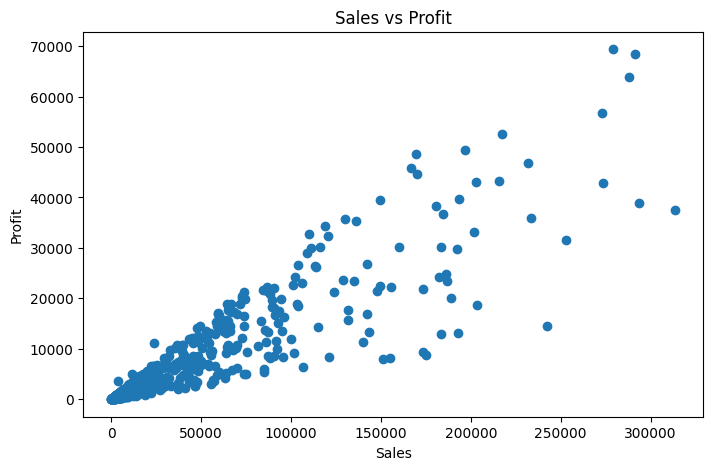

In [114]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(df["Sales"], df["Profit"])

plt.xlabel("Sales")
plt.ylabel("Profit")
plt.title("Sales vs Profit")

plt.show()

In [ ]:
category_sales = (
    df.groupby("Category")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

category_sales.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Category"
)

plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

In [ ]:
category_profit = (
    df.groupby("Category")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

category_profit.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Profit by Category"
)

plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)

plt.show()

In [ ]:
product_sales = (
    df.groupby("Product")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

product_sales.plot(
    kind="bar",
    figsize=(10, 6),
    title="Total Sales by Product"
)

plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)

plt.show()

In [ ]:
city_sales = (
    df.groupby("City")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

city_sales.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by City"
)

plt.xlabel("City")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

In [ ]:
payment_counts = df["Payment_Mode"].value_counts()

payment_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Orders by Payment Mode"
)

plt.xlabel("Payment Mode")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

In [121]:
df["Month"] = df["Order_Date"].dt.to_period("M")

In [ ]:
monthly_sales = (
    df.groupby("Month")["Sales"]
      .sum()
      .sort_index()
)

monthly_sales.plot(
    kind="line",
    figsize=(10, 5),
    marker="o",
    title="Monthly Sales Trend"
)

plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

In [ ]:
monthly_profit = (
    df.groupby("Month")["Profit"]
      .sum()
      .sort_index()
)

monthly_profit.plot(
    kind="line",
    figsize=(10, 5),
    marker="o",
    title="Monthly Profit Trend"
)

plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)

plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Sales"],
    df["Profit"]
)

plt.xlabel("Sales")
plt.ylabel("Profit")
plt.title("Sales vs Profit")

plt.show()

In [ ]:
top_products = (
    df.groupby("Product")["Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_products.plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 Products by Sales"
)

plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

In [ ]:
top_profit_products = (
    df.groupby("Product")["Profit"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

top_profit_products.plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 Products by Profit"
)

plt.xlabel("Product")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)

plt.show()

In [131]:
total_sales = df["Sales"].sum()

print("Total Sales:", total_sales)

Total Sales: 24437487.0


In [132]:
total_profit = df["Profit"].sum()

print("Total Profit:", total_profit)

Total Profit: 4284298.17


In [133]:
total_orders = df["Order_ID"].nunique()

print("Total Orders:", total_orders)

Total Orders: 796


In [134]:
average_order_value = total_sales / total_orders

print("Average Order Value:", average_order_value)

Average Order Value: 30700.360552763817


In [135]:
total_quantity = df["Quantity"].sum()

print("Total Quantity Sold:", total_quantity)

Total Quantity Sold: 2377.0


In [136]:
profit_margin = (total_profit / total_sales) * 100

print("Profit Margin:", profit_margin, "%")

Profit Margin: 17.53166424190834 %


In [137]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
average_order_value = total_sales / total_orders
total_quantity = df["Quantity"].sum()
profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", total_sales)
print("Total Profit:", total_profit)
print("Total Orders:", total_orders)
print("Average Order Value:", average_order_value)
print("Total Quantity Sold:", total_quantity)
print("Profit Margin:", profit_margin, "%")

Total Sales: 24437487.0
Total Profit: 4284298.17
Total Orders: 796
Average Order Value: 30700.360552763817
Total Quantity Sold: 2377.0
Profit Margin: 17.53166424190834 %


In [138]:
print("Highest Sales Category:")
print(df.groupby("Category")["Sales"].sum().idxmax())

print("\nHighest Profit Category:")
print(df.groupby("Category")["Profit"].sum().idxmax())

print("\nTop Product by Sales:")
print(df.groupby("Product")["Sales"].sum().idxmax())

print("\nTop City by Sales:")
print(df.groupby("City")["Sales"].sum().idxmax())

print("\nBest Sales Month:")
print(monthly_sales.idxmax())

print("\nBest Profit Month:")
print(monthly_profit.idxmax())

print("\nSales-Profit Correlation:")
print(df[["Sales", "Profit"]].corr().loc["Sales", "Profit"])

Highest Sales Category:
Electronics

Highest Profit Category:
Electronics

Top Product by Sales:
Smartphone

Top City by Sales:
Mumbai

Best Sales Month:
2025-12

Best Profit Month:
2025-12

Sales-Profit Correlation:
0.9095473706772471


In [139]:
df.groupby("Category")["Sales"].sum().idxmax()

'Electronics'

In [140]:
print("Final dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate Order IDs:", df["Order_ID"].duplicated().sum())

Final dataset shape: (796, 11)
Missing values: 8
Duplicate Order IDs: 0


In [141]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Payment_Mode    8
dtype: int64


In [142]:
df["Payment_Mode"] = df["Payment_Mode"].fillna("Unknown")

In [143]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate Order IDs:", df["Order_ID"].duplicated().sum())

Missing values: 0
Duplicate Order IDs: 0
